# TP3 : sécurité, analyse et visualisation

Sekou Camara, B2 Sup de Vinci Rennes

On reprend les collections MongoDB du TP2 (`raw_commandes` et `raw_payments`). On remplace l'identifiant client par un pseudonyme, on exporte des fichiers Parquet sans identifiant direct, puis on fait trois graphiques.

Avant de lancer Jupyter, la clé secrète doit être définie dans le terminal avec `export PSEUDO_KEY="..."`. Elle n'est jamais écrite dans ce notebook.

## Atelier 1 : pseudonymiser les identifiants clients

### 1. Charger la clé et définir la fonction

In [1]:
import os
import hmac
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from pymongo import MongoClient

PSEUDO_KEY = os.environ.get("PSEUDO_KEY")
if not PSEUDO_KEY:
    raise ValueError("La variable PSEUDO_KEY n'est pas définie dans le terminal")
print("Clé chargée :", PSEUDO_KEY is not None)


def pseudonymiser(valeur):
    return hmac.new(PSEUDO_KEY.encode(), str(valeur).encode(), hashlib.sha256).hexdigest()[:16]

Clé chargée : True


La fonction prend l'identifiant, le passe dans HMAC avec la clé et l'algorithme SHA 256, et garde les 16 premiers caractères du résultat. Sans la clé, on ne peut pas refaire le calcul.

### 2. Charger les données depuis MongoDB

In [2]:
client = MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=5000)
db = client["commerce"]

commandes = pd.DataFrame(list(db["raw_commandes"].find({}, {"_id": 0})))
paiements = pd.DataFrame(list(db["raw_payments"].find({}, {"_id": 0})))
paiements = paiements.rename(columns={"status": "payment_status", "attempted_at": "payment_date"})

print("Commandes :", commandes.shape)
print("Paiements :", paiements.shape)

Commandes : (800, 16)
Paiements : (208, 8)


Dans notre collection les colonnes s'appellent `status` et `attempted_at`. On les renomme en `payment_status` et `payment_date` pour suivre les noms du TP3.

### 3. Appliquer la pseudonymisation

In [3]:
commandes["user_id_pseudo"] = commandes["user_id"].apply(pseudonymiser)
paiements["user_id_pseudo"] = paiements["user_id"].apply(pseudonymiser)

commandes[["user_id", "user_id_pseudo"]].drop_duplicates().head(5)

,user_id,user_id_pseudo
0,1,d4bf34854f711737
4,2,c9ec173c1a593488
6,3,59a9c71c59289817
12,4,096ffe9ea76b8e18
14,5,e0efa91ec774b17d


### 4. Vérifications

In [4]:
pseudos_par_client = commandes.groupby("user_id")["user_id_pseudo"].nunique().max()
print("Nombre de pseudonymes différents pour un même client :", pseudos_par_client)

print("Clients :", commandes["user_id"].nunique(), "et pseudonymes :", commandes["user_id_pseudo"].nunique())

lien = commandes[["user_id", "user_id_pseudo"]].drop_duplicates().merge(
    paiements[["user_id", "user_id_pseudo"]], on="user_id", suffixes=("_commandes", "_paiements")
)
identiques = (lien["user_id_pseudo_commandes"] == lien["user_id_pseudo_paiements"]).sum()
print("Clients avec le même pseudonyme dans les commandes et les paiements :", identiques, "sur", len(lien))

Nombre de pseudonymes différents pour un même client : 1
Clients : 208 et pseudonymes : 208
Clients avec le même pseudonyme dans les commandes et les paiements : 208 sur 208


In [5]:
exemple = commandes["user_id"].iloc[0]
commandes.loc[commandes["user_id"] == exemple, ["user_id", "product_title", "user_id_pseudo"]]

,user_id,product_title,user_id_pseudo
0,1,Blue Frock,d4bf34854f711737
1,1,Generic Motorcycle,d4bf34854f711737
2,1,iPhone 6,d4bf34854f711737
3,1,Baseball Ball,d4bf34854f711737


In [6]:
commandes.groupby("user_id_pseudo")["discounted_line_total"].sum().sort_values(ascending=False).head(5)

user_id_pseudo
bb67fe728ebfc664    155507.16
aba89b9bb886486d    130175.28
bd25cb2af83e68c3    129783.31
dfdf5f033953d891    125679.00
084bc72ee5fd9dba    125461.58
Name: discounted_line_total, dtype: float64

On voit que les calculs par client marchent toujours : on regroupe sur `user_id_pseudo` au lieu de `user_id`.

### Réponses

**1. Avant et après.** Le tableau du point 3 montre des `user_id` (1, 2, 3...) à côté de leur pseudonyme, une suite de 16 caractères.

**2. Pourquoi le même pseudonyme partout ?** HMAC donne toujours le même résultat avec le même identifiant et la même clé. Un client qui a 4 lignes dans son panier a 4 fois le même pseudonyme, et on retrouve ce pseudonyme dans les paiements parce qu'on a utilisé la même clé. On peut donc toujours regrouper et relier les tables.

**3. Pourquoi ne pas mettre la clé sur GitHub ?** Avec la clé, n'importe qui peut recalculer le pseudonyme de chaque `user_id` (1, 2, 3... jusqu'à 208) et retrouver qui est qui. La clé reste donc dans le terminal, jamais dans le notebook, les fichiers de résultats ou le dépôt Git.

**4. Limites et précautions.** C'est une pseudonymisation, pas une anonymisation : avec la clé on peut revenir en arrière, et les données restent des données personnelles au sens du RGPD. D'autres colonnes peuvent aussi trahir le client. Ici `cart_id` est égal à `user_id` et `order_id` contient le même numéro, donc on les pseudonymise aussi. On retire `username`. Les fichiers Parquet restent à protéger : accès limité, pas de partage public.

## Atelier 2 (1/2) : préparer les données

In [7]:
commandes["discounted_line_total"] = pd.to_numeric(commandes["discounted_line_total"], errors="coerce")
commandes["order_date"] = pd.to_datetime(commandes["order_date"], errors="coerce")
paiements["amount"] = pd.to_numeric(paiements["amount"], errors="coerce")
paiements["payment_date"] = pd.to_datetime(paiements["payment_date"], errors="coerce")

print("Montants ou dates invalides dans les commandes :", commandes[["discounted_line_total", "order_date"]].isna().any(axis=1).sum())
print("Montants ou dates invalides dans les paiements :", paiements[["amount", "payment_date"]].isna().any(axis=1).sum())

commandes = commandes.dropna(subset=["discounted_line_total", "order_date"])
paiements = paiements.dropna(subset=["amount", "payment_date"])

Montants ou dates invalides dans les commandes : 0
Montants ou dates invalides dans les paiements : 0


In [8]:
commandes["cart_id_pseudo"] = commandes["cart_id"].apply(pseudonymiser)
paiements["cart_id_pseudo"] = paiements["cart_id"].apply(pseudonymiser)

commandes_pseudo = commandes.drop(columns=["user_id", "username", "cart_id", "order_id"])
paiements_pseudo = paiements.drop(columns=["user_id", "cart_id", "payment_id"])

Path("data").mkdir(exist_ok=True)
commandes_pseudo.to_parquet("data/commandes_pseudo.parquet", index=False)
paiements_pseudo.to_parquet("data/paiements_pseudo.parquet", index=False)

print("Colonnes commandes :", list(commandes_pseudo.columns))
print("Colonnes paiements :", list(paiements_pseudo.columns))

Colonnes commandes : ['product_id', 'product_title', 'category', 'brand', 'quantity', 'unit_price', 'line_total', 'discount_percentage', 'discounted_line_total', 'cart_total', 'cart_discounted_total', 'order_date', 'user_id_pseudo', 'cart_id_pseudo']
Colonnes paiements : ['amount', 'nb_lignes', 'payment_date', 'payment_status', 'is_cashed', 'user_id_pseudo', 'cart_id_pseudo']


Les deux fichiers Parquet ne contiennent plus `user_id`, `username`, `cart_id`, `order_id` ni `payment_id`. Ils ne contiennent pas la clé non plus.

## Atelier 2 (2/2) : les trois graphiques

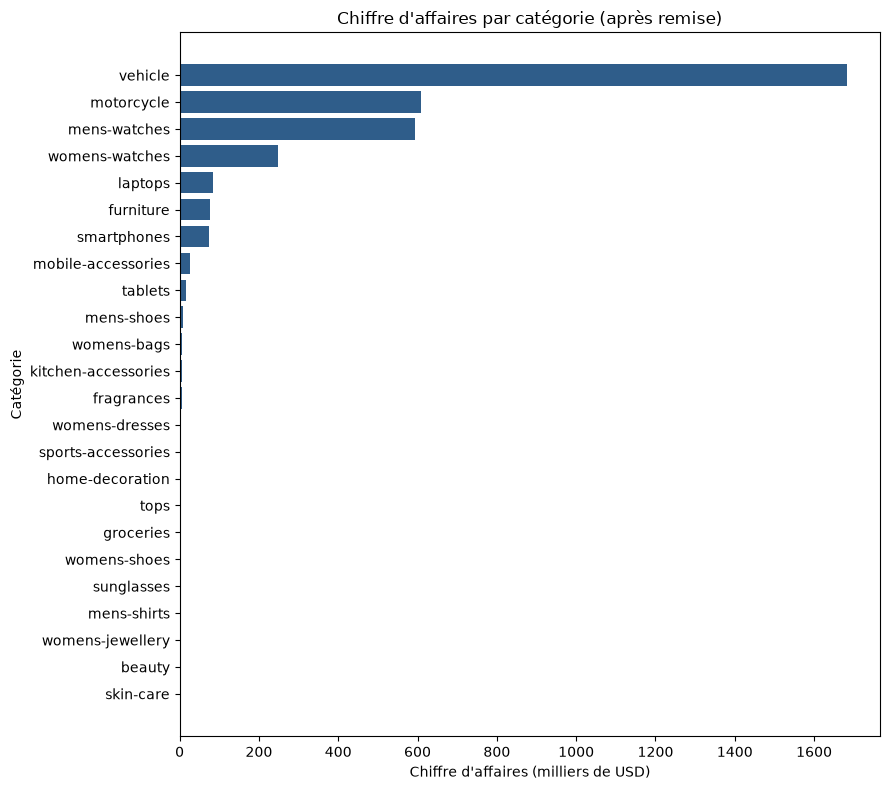

In [9]:
Path("graphiques").mkdir(exist_ok=True)

ca_categorie = commandes_pseudo.groupby("category")["discounted_line_total"].sum().sort_values()

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(ca_categorie.index, ca_categorie.values / 1000, color="#2f5d8a")
ax.set_title("Chiffre d'affaires par catégorie (après remise)")
ax.set_xlabel("Chiffre d'affaires (milliers de USD)")
ax.set_ylabel("Catégorie")
plt.tight_layout()
plt.savefig("graphiques/ca_par_categorie.png", dpi=150)
plt.show()

**Interprétation.** Les véhicules font à eux seuls 1,68 million de USD, presque la moitié du chiffre d'affaires. Avec les motos et les montres homme, trois catégories font 83 % du total. Les catégories du quotidien comme l'alimentation ou la cuisine sont dans beaucoup de paniers mais rapportent très peu. Pour la boutique, le chiffre d'affaires dépend donc de quelques produits très chers.

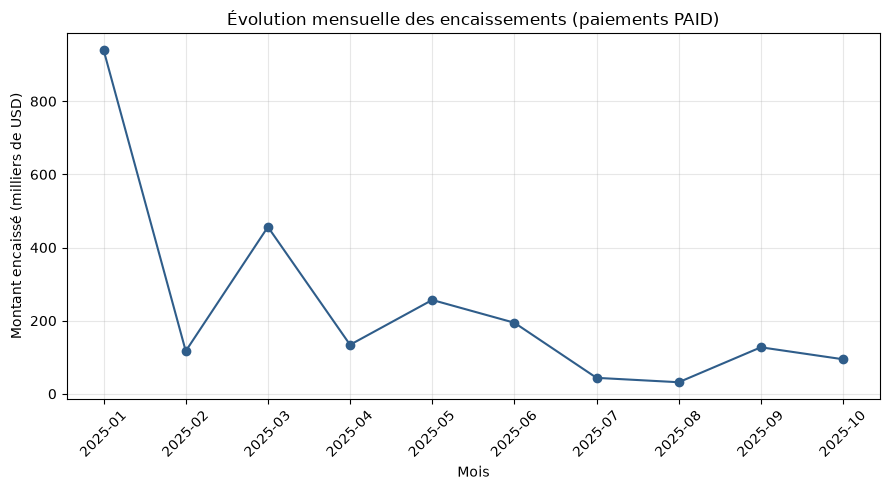

In [10]:
payes = paiements_pseudo[paiements_pseudo["payment_status"] == "PAID"]
mensuel = payes.groupby(payes["payment_date"].dt.to_period("M"))["amount"].sum()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(mensuel.index.astype(str), mensuel.values / 1000, marker="o", color="#2f5d8a")
ax.set_title("Évolution mensuelle des encaissements (paiements PAID)")
ax.set_xlabel("Mois")
ax.set_ylabel("Montant encaissé (milliers de USD)")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("graphiques/evolution_mensuelle.png", dpi=150)
plt.show()

**Interprétation.** Janvier 2025 est très haut (940 000 USD), puis les montants sont plus bas et irréguliers, avec un petit pic en mars et un creux en été. Il n'y a plus rien après octobre. Ce n'est pas une vraie saison des ventes : la date de paiement vient de la date la plus ancienne du panier, et ces dates ont été tirées au hasard par le script de collecte. Avec de vraies dates, cette courbe servirait à repérer les mois forts et à prévoir les stocks.

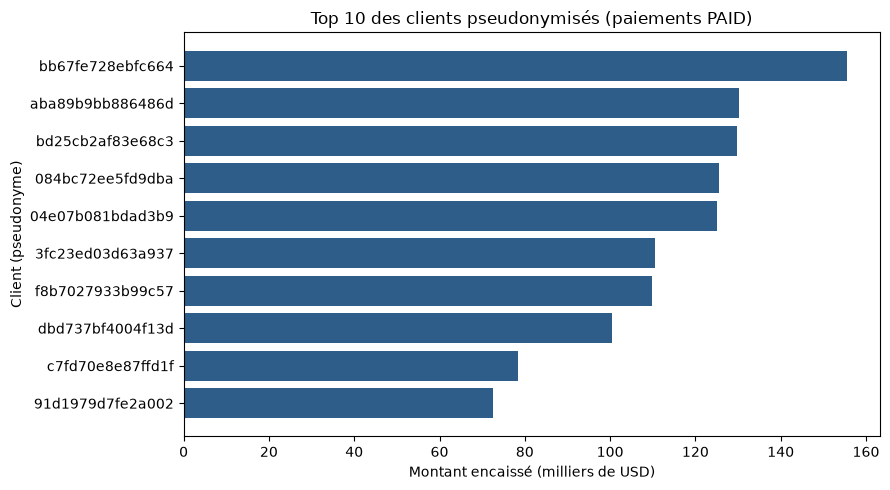

Part du top 10 dans l'encaissé : 47.5 %


In [11]:
top10 = payes.groupby("user_id_pseudo")["amount"].sum().sort_values().tail(10)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10.index, top10.values / 1000, color="#2f5d8a")
ax.set_title("Top 10 des clients pseudonymisés (paiements PAID)")
ax.set_xlabel("Montant encaissé (milliers de USD)")
ax.set_ylabel("Client (pseudonyme)")
plt.tight_layout()
plt.savefig("graphiques/top10_clients.png", dpi=150)
plt.show()

print("Part du top 10 dans l'encaissé :", round(100 * top10.sum() / payes["amount"].sum(), 1), "%")

**Interprétation.** Les 10 meilleurs clients font presque la moitié de l'argent encaissé (47,5 %). Ce sont les clients qui ont un véhicule ou une moto dans leur panier. On voit seulement leur pseudonyme : on peut analyser leur poids sans savoir qui ils sont. Pour une vraie boutique, ce serait les clients à fidéliser en priorité.

## Vérification avec le TP2

In [12]:
print("Chiffre d'affaires des lignes :", round(commandes_pseudo["discounted_line_total"].sum(), 2), "USD")
print("Encaissé PAID :", round(payes["amount"].sum(), 2), "USD")
print("Paiements par statut :")
print(paiements_pseudo["payment_status"].value_counts())

Chiffre d'affaires des lignes : 3456709.58 USD
Encaissé PAID : 2396066.11 USD
Paiements par statut :
payment_status
PAID       148
REFUSED     43
PENDING     17
Name: count, dtype: int64


On retrouve les mêmes chiffres qu'au TP2 avec Spark : 3 456 709,58 USD de chiffre d'affaires, 2 396 066,11 USD encaissés, 148 PAID, 43 REFUSED et 17 PENDING.